<a href="https://colab.research.google.com/github/An-n-nie/Fish_Biomass/blob/main/tabular/Fish_Biomass_Investigation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Objective

####  The purpose of this notebook is to investigate whether selected ML models can retain any predictive power if we completely remove all of the suspected columns for data leakage. The pipeline will follow most of what was covered in our previous primary notebook with the distinction of a leakage-free setting.

In [43]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_validate,
    GridSearchCV)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score)

In [12]:
# Load data
df = pd.read_csv('fish_data.csv')

####  As previously established, there were no missing values so no imputations were used. There were no duplicates so no removal needed. The target was skewed but we kept it for ease of interpretation. A lot of columns were dropped because they were id columns and constants that provided no variation and no additional predictive power to our models - this notebook will follow that route.

In [13]:
# dropping constant value columns
constant_columns = [col for col in df.columns if df[col].nunique() == 1]

df.drop(columns=constant_columns, inplace=True)

In [14]:
df.columns

Index(['day', 'region', 'island', 'side', 'id_reef', 'reef', 'reef_joined',
       'protection_status', 'latitude', 'longitude', 'transect', 'taxa3',
       'family', 'trophic_group', 'trophic_level', 'functional_groups',
       'a_ord', 'b_pen', 'species', 'quantity', 'size', 'biomass'],
      dtype='object')

In [15]:
#Dropping id columns

df = df.drop(columns=['reef_joined', 'id_reef'])

#### The columns suspected of data leakage are: a_ord, b_pen (direct measures for length-weight calculations), size, and quantity. As an investigation, we will drop those columns and see if the remaining data and model can still predict our regression target - fish biomass.

In [16]:
# Dropping suspected columns
df = df.drop(columns=['a_ord', "b_pen", "size", "quantity"])
df.columns

Index(['day', 'region', 'island', 'side', 'reef', 'protection_status',
       'latitude', 'longitude', 'transect', 'taxa3', 'family', 'trophic_group',
       'trophic_level', 'functional_groups', 'species', 'biomass'],
      dtype='object')

#### The next sections will follow our previously-established pipelines

In [26]:
# Splitting the dataset

x = df.drop(columns=['biomass'])
y = df['biomass']

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42)

In [20]:
print(f"x_train shape: {x_train.shape}",
      f"\nx_test shape: {x_test.shape}",
      f"\ny_train shape: {y_train.shape}",
      f"\ny_test shape: {y_test.shape}")

x_train shape: (1944, 15) 
x_test shape: (487, 15) 
y_train shape: (1944,) 
y_test shape: (487,)


In [23]:
# set up columns types

numerical = x_train.select_dtypes(include=["float64", "int64"]).columns.tolist()
categorical = x_train.select_dtypes(include="object").columns.tolist()

In [38]:
# preprocessing
# standard scale numerical columns, onehot encode categorical columns

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False),
         categorical)] )

In [27]:
# models to be used

models = {
    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(n_estimators=200,random_state=42,n_jobs=-1),

    "Gradient Boosting": GradientBoostingRegressor(random_state=42),

    "XGBoost": XGBRegressor(objective="reg:squarederror", n_estimators=200,
        random_state=42, n_jobs=-1, verbosity=0)}

In [29]:
# make a function to apply pipeline to models

def make_pipeline(model, use_pca=False):

    steps = [
        ("preprocessor", preprocessor),
        ("scaler", StandardScaler()) ]

    if use_pca:
        steps.append( ("pca", PCA(n_components=0.95)) )
    else:
        steps.append( ("pca", "passthrough") )

    steps.append(("model", model))

    return Pipeline(steps)

In [ ]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

cv_results = []

for model_name, model in models.items():

    for use_pca in [False, True]:

        pipe = make_pipeline(
            model=model,
            use_pca=use_pca
        )

        scores = cross_validate(
            pipe,
            X_train,
            y_train,
            cv=cv,
            scoring=scoring,
            n_jobs=-1,
            error_score="raise"
        )

        cv_results.append({
            "Model": model_name,
            "PCA": "With PCA" if use_pca else "Without PCA",
            "MAE": -scores["test_MAE"].mean(),
            "RMSE": -scores["test_RMSE"].mean(),
            "R²": scores["test_R2"].mean(),
            "R² SD": scores["test_R2"].std()
        })

cv_results_df = pd.DataFrame(cv_results)

cv_results_df = cv_results_df.sort_values(
    "R²",
    ascending=False
).reset_index(drop=True)

display(cv_results_df.round(4))

In [50]:
# Set up cross validation

cv = KFold( n_splits=5, shuffle=True, random_state=42)

#Set up scoring metrics

scoring = {
    "MAE" : "neg_mean_absolute_error",
    "RMSE" : "neg_root_mean_squared_error",
    "R2": "r2"}

In [51]:
# Run cross validation

cv_results = []

for model_name, model in models.items():
  for use_pca in [False, True]:
    pipe = make_pipeline(model=model, use_pca=use_pca)

    score= cross_validate(pipe, x_train, y_train, cv=cv, scoring=scoring,
                          n_jobs=-1, error_score="raise")
    cv_results.append({
        "Model": model_name,
        "PCA": "With PCA" if use_pca else "Without PCA",
        "MAE": -score["test_MAE"].mean(),
        "RMSE": -score["test_RMSE"].mean(),
        "R²": score["test_R2"].mean(),
        "R² SD": score["test_R2"].std()  })

  cv_df = pd.DataFrame(cv_results)
  cv_df = cv_df.sort_values("R²", ascending=False).reset_index(drop=True)
  display(cv_df.round(3))

,Model,PCA,MAE,RMSE,R²,R² SD
0,Linear Regression,With PCA,0.027,0.082,-0.210,0.777
1,Linear Regression,Without PCA,0.027,0.082,-0.219,0.782


,Model,PCA,MAE,RMSE,R²,R² SD
0,Linear Regression,With PCA,0.027,0.082,-0.210,0.777
1,Linear Regression,Without PCA,0.027,0.082,-0.219,0.782
2,Random Forest,With PCA,0.024,0.088,-0.634,1.586
3,Random Forest,Without PCA,0.023,0.088,-0.764,1.941


,Model,PCA,MAE,RMSE,R²,R² SD
0,Linear Regression,With PCA,0.027,0.082,-0.210,0.777
1,Linear Regression,Without PCA,0.027,0.082,-0.219,0.782
2,Random Forest,With PCA,0.024,0.088,-0.634,1.586
3,Random Forest,Without PCA,0.023,0.088,-0.764,1.941
4,Gradient Boosting,With PCA,0.025,0.096,-1.366,3.004
5,Gradient Boosting,Without PCA,0.026,0.096,-1.403,3.162


,Model,PCA,MAE,RMSE,R²,R² SD
0,Linear Regression,With PCA,0.027,0.082,-0.210,0.777
1,Linear Regression,Without PCA,0.027,0.082,-0.219,0.782
2,Random Forest,With PCA,0.024,0.088,-0.634,1.586
3,Random Forest,Without PCA,0.023,0.088,-0.764,1.941
4,Gradient Boosting,With PCA,0.025,0.096,-1.366,3.004
5,Gradient Boosting,Without PCA,0.026,0.096,-1.403,3.162
6,XGBoost,With PCA,0.026,0.098,-1.519,3.235
7,XGBoost,Without PCA,0.024,0.098,-1.664,3.616


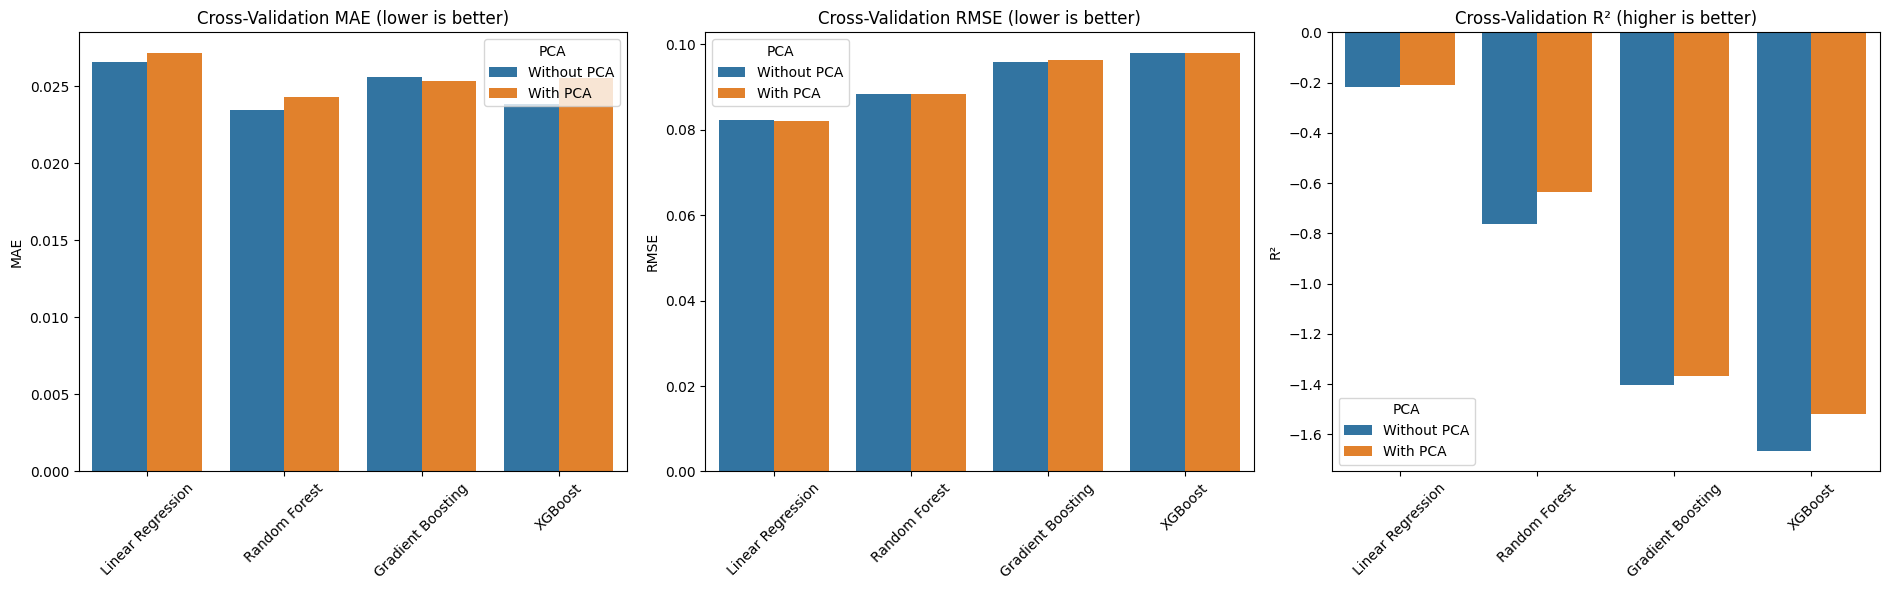

In [52]:
# Visualize the cv results by model

model_order = list(models.keys())

fig, axes = plt.subplots(1, 3, figsize=(19, 6))

metrics = ["MAE", "RMSE", "R²"]
titles = [
    "Cross-Validation MAE (lower is better)",
    "Cross-Validation RMSE (lower is better)",
    "Cross-Validation R² (higher is better)" ]

for ax, metric, title in zip(axes, metrics, titles):
    sns.barplot(
        data=cv_df, x="Model", y=metric, hue="PCA",
        order=model_order,
        hue_order=["Without PCA", "With PCA"], ax=ax)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [54]:
# Select top 3 models for tuning

best_by_model = (cv_df.sort_values("R²", ascending=False)
    .groupby("Model", as_index=False).first().sort_values("R²", ascending=False))

display(best_by_model.round(4))

top3 = best_by_model["Model"].head(3).tolist()

print(f"Top selected models for tuning: {top3}")

,Model,PCA,MAE,RMSE,R²,R² SD
1,Linear Regression,With PCA,0.0271,0.0820,-0.2101,0.7772
2,Random Forest,With PCA,0.0243,0.0883,-0.6335,1.5859
0,Gradient Boosting,With PCA,0.0254,0.0963,-1.3661,3.0042
3,XGBoost,With PCA,0.0256,0.0979,-1.5190,3.2350


Top selected models for tuning: ['Linear Regression', 'Random Forest', 'Gradient Boosting']


In [55]:
# Hyperparameter to tune for top models

param_grids = {
    "Linear Regression": {
        "model__fit_intercept": [True, False]},

    "Random Forest": {
        "model__n_estimators": [200, 400],
        "model__max_depth": [None, 10, 20],
        "model__min_samples_leaf": [1, 2, 4],
        "model__max_features": [1.0, 0.7] },

    "Gradient Boosting": {
        "model__n_estimators": [100, 200],
        "model__learning_rate": [0.03, 0.1],
        "model__max_depth": [2, 3],
        "model__min_samples_leaf": [2, 5] }  }

In [59]:
# running the tunning process

tuned_models = {}
tuning_results = []

for model_name in top3:

    base_pipe = make_pipeline(model=models[model_name],use_pca=False)

    grid = dict(param_grids[model_name])

    # Compare no PCA against PCA retaining 95% variance
    # this way each selected model can decide for itself whether PCA help
    grid["pca"] = ["passthrough",PCA(n_components=0.95)]

    search = GridSearchCV(estimator=base_pipe, param_grid=grid,scoring="r2",
        cv=cv,refit=True,error_score="raise")

    search.fit(x_train, y_train)

    tuned_models[model_name] = search.best_estimator_

    tuning_results.append({
        "Model": model_name,
        "Best CV R²": search.best_score_,
        "Best PCA setting": (
            "With PCA"
            if isinstance(search.best_params_["pca"],PCA)
            else "Without PCA"),
        "Best parameters": search.best_params_ })

tuning_results_df = pd.DataFrame(tuning_results)

display(tuning_results_df[["Model", "Best CV R²",
                           "Best PCA setting"]].round(4))

for result in tuning_results:
    print(f"\n{result['Model']}")
    print(result["Best parameters"])

,Model,Best CV R²,Best PCA setting
0,Linear Regression,-0.2101,With PCA
1,Random Forest,-0.0115,With PCA
2,Gradient Boosting,-0.1065,Without PCA



Linear Regression
{'model__fit_intercept': True, 'pca': PCA(n_components=0.95)}

Random Forest
{'model__max_depth': 20, 'model__max_features': 0.7, 'model__min_samples_leaf': 4, 'model__n_estimators': 400, 'pca': PCA(n_components=0.95)}

Gradient Boosting
{'model__learning_rate': 0.03, 'model__max_depth': 3, 'model__min_samples_leaf': 5, 'model__n_estimators': 100, 'pca': 'passthrough'}


In [61]:
# Final evaluation on test set

test_results = []

for model_name, pipe in tuned_models.items():

    predictions = pipe.predict(x_test)

    test_results.append({
        "Model": model_name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R²": r2_score(y_test, predictions) })

test_results_df = pd.DataFrame(test_results)

display(test_results_df.sort_values("R²", ascending=False).round(4) )

,Model,MAE,RMSE,R²
0,Linear Regression,0.0244,0.0638,0.2469
1,Random Forest,0.0218,0.0642,0.2377
2,Gradient Boosting,0.0279,0.0683,0.1364


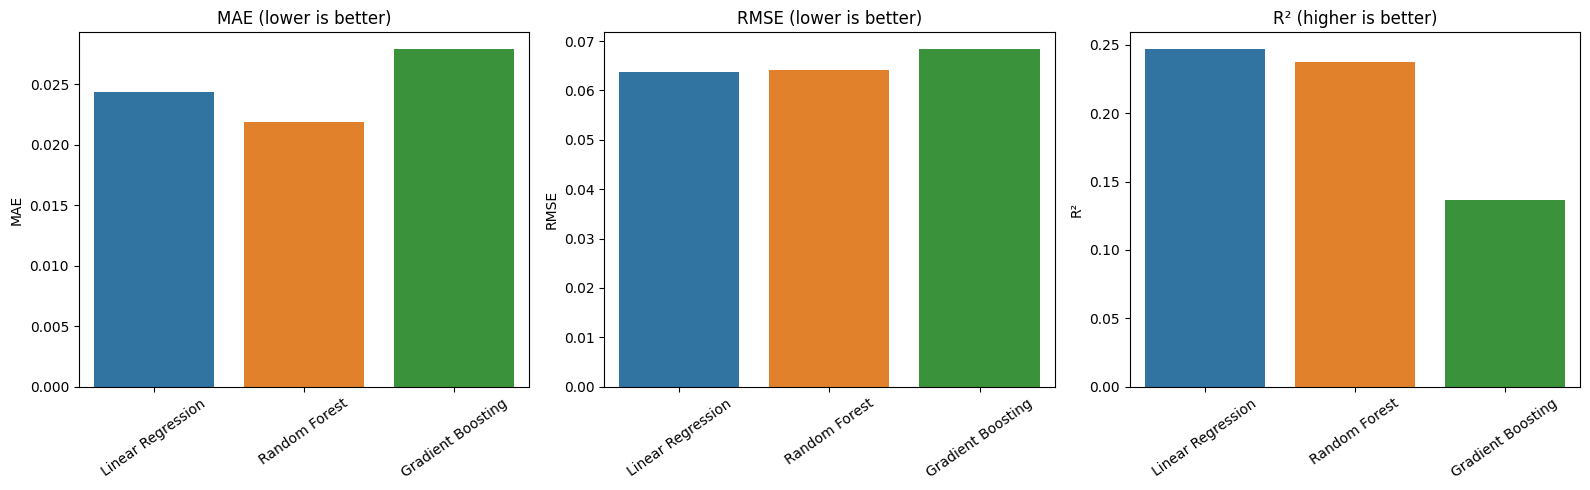

In [62]:
# Test metrics graph

plot_df = test_results_df.melt(id_vars="Model",value_vars=["MAE", "RMSE", "R²"],
    var_name="Metric", value_name="Score")

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

metric_titles = {
    "MAE": "MAE (lower is better)",
    "RMSE": "RMSE (lower is better)",
    "R²": "R² (higher is better)"}

for ax, metric in zip(axes, ["MAE", "RMSE", "R²"]):
    subset = plot_df[plot_df["Metric"] == metric]

    sns.barplot(data=subset, x="Model", y="Score",
                hue="Model", legend=False,ax=ax)
    ax.set_title(metric_titles[metric])
    ax.set_xlabel("")
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()

In [64]:
# Compare original vs tuned models' performance
comparison = []

for model_name in top3:

    initial_best = best_by_model[
        best_by_model["Model"] == model_name
    ].iloc[0]

    tuned = tuning_results_df[
        tuning_results_df["Model"] == model_name
    ].iloc[0]

    comparison.append({
        "Model": model_name,
        "Initial CV R²": initial_best["R²"],
        "Tuned CV R²": tuned["Best CV R²"],
        "Change in CV R²": (
            tuned["Best CV R²"] - initial_best["R²"]
        )
    })

comparison_df = pd.DataFrame(comparison)

display(comparison_df.round(4))

,Model,Initial CV R²,Tuned CV R²,Change in CV R²
0,Linear Regression,-0.2101,-0.2101,-0.0000
1,Random Forest,-0.6335,-0.0115,0.6221
2,Gradient Boosting,-1.3661,-0.1065,1.2597


#### It appears even after running cross validation and tuning hyperparameters, our current selection of models cannot perform well (the highest R squared score was 0.24 from Linear Regression). Since we opted for the best performance with tuning and tried to achieve the most unbiased results with validation, the results suggest that our models are not able to extract much more predictive power or signals from our current set of data. This calls for more informative values (e.g. measure of primary production, water temperature, depth of reef location, reef type/curvature, fishing activity, etc.) so that future modeling can be improved.